
# Fake News Classification with Machine Learning

## Project Overview

Fake news can spread misinformation quickly through online platforms.  
The goal of this project is to build a simple machine learning model that classifies a news article as **Fake** or **Real**.

This is a **Binary Classification** and **Natural Language Processing (NLP)** problem

### Dataset
- **Name:** WELFake Dataset
- **Rows:** 72,134 news articles in the original dataset
- **Main features:** `title`, `text`
- **Target:** `label`
- **Label mapping:** `0 = Fake`, `1 = Real`
- **Kaggle:** https://www.kaggle.com/datasets/saurabhshahane/fake-news-classification
- **Original dataset / Zenodo:** https://zenodo.org/records/4561253
- **Paper:** P. K. Verma et al., *WELFake: Word Embedding Over Linguistic Features for Fake News Detection*, IEEE Transactions on Computational Social Systems (2021)

### Project Workflow
1. Load the dataset
2. Inspect and clean the data
3. Explore the target classes
4. Convert text into numerical features with TF-IDF
5. Train two simple classification models
6. Evaluate the models
7. Select the best model
8. Test a custom news example


## 1. Import Libraries

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42


## 2. Load the Dataset

In [2]:

# The notebook works if the CSV is:
# 1) inside the data/ folder, or
# 2) in the same folder as this notebook.

possible_paths = [
    Path("data/WELFake_Dataset.csv"),
    Path("WELFake_Dataset.csv")
]

data_path = next((path for path in possible_paths if path.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        "WELFake_Dataset.csv was not found. "
        "Place it inside the data/ folder or next to the notebook."
    )

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (72134, 4)


,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


## 3. Understand the Data

In [3]:

print("Columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isna().sum())

print("\nLabel distribution:")
print(df["label"].value_counts().sort_index())


Columns:
['Unnamed: 0', 'title', 'text', 'label']

Missing values:
Unnamed: 0      0
title         558
text           39
label           0
dtype: int64

Label distribution:
label
0    35028
1    37106
Name: count, dtype: int64



### What do the columns mean?

- `title`: headline of the news article
- `text`: article content
- `label`: target variable
  - `0` = Fake
  - `1` = Real
- `Unnamed: 0`: old row index and not useful for prediction


## 4. Data Cleaning

In [4]:

data = df.copy()

# Remove the old index column
if "Unnamed: 0" in data.columns:
    data = data.drop(columns=["Unnamed: 0"])

# Replace missing text values with empty strings
data["title"] = data["title"].fillna("")
data["text"] = data["text"].fillna("")

# Remove exact duplicate articles to reduce train/test leakage
data = data.drop_duplicates(subset=["title", "text"]).copy()

# Combine headline and the beginning of the article.
# Limiting the text keeps this learning project fast on a normal computer.
data["content"] = (
    data["title"].str.strip()
    + " "
    + data["text"].str[:1000].str.strip()
).str.strip()

# Remove rows without any usable text
data = data[data["content"].str.len() > 0].copy()

print("Cleaned dataset shape:", data.shape)
data.head()


Cleaned dataset shape: (63678, 4)


,title,text,label,content
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1,LAW ENFORCEMENT ON HIGH ALERT Following Threat...
1,,Did they post their votes for Hillary already?,1,Did they post their votes for Hillary already?
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...
3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0,"Bobby Jindal, raised Hindu, uses story of Chri..."
4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1,SATAN 2: Russia unvelis an image of its terrif...


## 5. Exploratory Data Analysis

label
Fake    34791
Real    28887
Name: count, dtype: int64


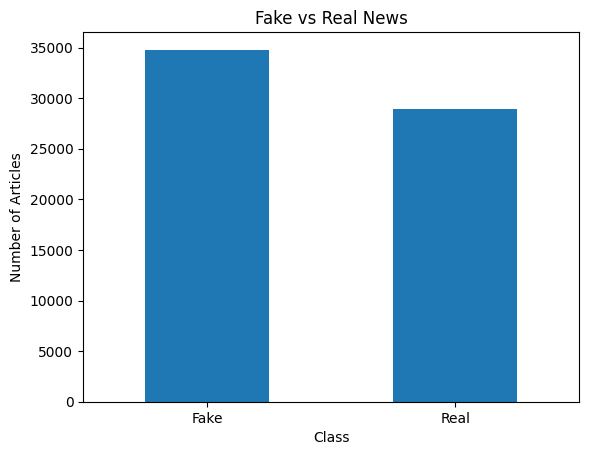

In [5]:

label_counts = (
    data["label"]
    .map({0: "Fake", 1: "Real"})
    .value_counts()
    .reindex(["Fake", "Real"])
)

print(label_counts)

label_counts.plot(kind="bar", title="Fake vs Real News")
plt.xlabel("Class")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)
plt.show()



The two classes are reasonably balanced, so a special resampling method is not necessary for this short project.


## 6. Prepare Data for Machine Learning

In [6]:

# Use a sample to keep the notebook quick and practical.
# Set SAMPLE_SIZE = None if you want to train on the full cleaned dataset.
SAMPLE_SIZE = 20000

if SAMPLE_SIZE is not None and len(data) > SAMPLE_SIZE:
    model_data = data.sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE)
else:
    model_data = data.copy()

X = model_data["content"]
y = model_data["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))


Training rows: 16000
Test rows: 4000



## 7. Convert Text to Numbers with TF-IDF

Machine learning models cannot directly understand text.  
**TF-IDF** converts words into numerical features and gives more importance to informative words.

This project uses a limited number of features so the notebook remains fast.


In [7]:

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=12000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF training matrix:", X_train_tfidf.shape)


TF-IDF training matrix: (16000, 12000)



## 8. Train Classification Models

We compare two simple models:

### Multinomial Naive Bayes
- Very fast
- Common baseline for text classification
- Easy to understand

### Logistic Regression
- Works very well with high-dimensional sparse TF-IDF features
- Fast and reliable
- Easy to interpret compared with deep learning


In [8]:

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(
        max_iter=500,
        random_state=RANDOM_STATE
    )
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    predictions = model.predict(X_test_tfidf)

    accuracy = accuracy_score(y_test, predictions)
    f1 = f1_score(y_test, predictions, average="weighted")

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "F1 Score": f1
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

results_df


,Model,Accuracy,F1 Score
0,Logistic Regression,0.9210,0.921085
1,Naive Bayes,0.8555,0.855775


## 9. Evaluate the Best Model

In [9]:

best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test_tfidf)

print("Best model:", best_model_name)
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        best_predictions,
        target_names=["Fake", "Real"],
        digits=3
    )
)


Best model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

        Fake      0.938     0.917     0.927      2196
        Real      0.901     0.926     0.914      1804

    accuracy                          0.921      4000
   macro avg      0.920     0.921     0.920      4000
weighted avg      0.921     0.921     0.921      4000



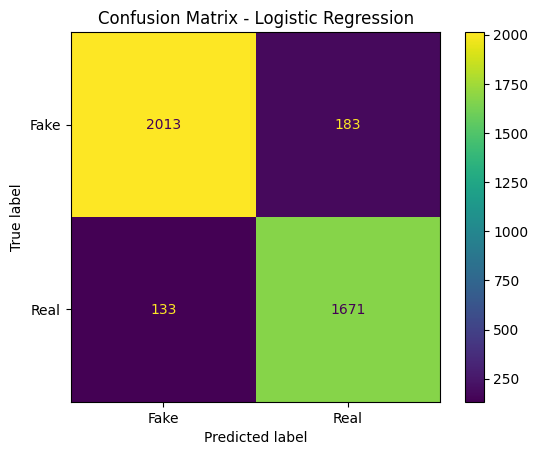

In [10]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=["Fake", "Real"]
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()



### How to read the results

- **Accuracy:** percentage of all predictions that were correct
- **Precision:** when the model predicts a class, how often it is correct
- **Recall:** how many examples of a class the model finds
- **F1 Score:** balance between Precision and Recall
- **Confusion Matrix:** shows correct and incorrect predictions for both classes


## 10. Test the Model with Your Own News Text

In [11]:

def predict_news(title, text=""):
    content = f"{title} {text[:1000]}".strip()
    content_tfidf = tfidf.transform([content])

    prediction = best_model.predict(content_tfidf)[0]
    label = "Real" if prediction == 1 else "Fake"

    return label

example_title = "Government announces a new economic policy after parliament vote"
print("Prediction:", predict_news(example_title))


Prediction: Fake



## Conclusion

This project built a simple **Fake News Classification** pipeline using NLP and machine learning.

The workflow included:
- cleaning the WELFake dataset,
- removing duplicate articles,
- combining title and article text,
- converting text with TF-IDF,
- comparing Multinomial Naive Bayes and Logistic Regression,
- evaluating the best model with classification metrics and a confusion matrix.

For this type of sparse text data, **Logistic Regression is usually a strong classical baseline**.  
Deep learning models such as LSTM or BERT could be tested later, but they require more computation and are not necessary for a short introductory project.

### Important Limitation

The model learns patterns from the training dataset. A prediction is **not a fact-check** and should not be treated as proof that a news story is true or false.



## References

1. Verma, P. K., Agrawal, P., Amorim, I., & Prodan, R. (2021).  
   *WELFake: Word Embedding Over Linguistic Features for Fake News Detection.*  
   IEEE Transactions on Computational Social Systems.  
   DOI: https://doi.org/10.1109/TCSS.2021.3068519

2. WELFake Dataset on Zenodo:  
   https://zenodo.org/records/4561253

3. Kaggle - Fake News Classification / WELFake Dataset:  
   https://www.kaggle.com/datasets/saurabhshahane/fake-news-classification

4. Aman Kharwal - Fake News Detection with Machine Learning:  
   https://amanxai.com/2021/06/30/fake-news-detection-with-machine-learning/
